In [1]:
%pip install ICIW_Plots
%pip install cma
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
import pandas as pd
import glob
from scipy.constants import R
from scipy.integrate import solve_ivp
from scipy.signal import correlate, correlation_lags
from pathlib import Path
import sys
import inspect


from AZA_THB_solver import *
from AZA_THB_tools import *
from AZA_THB_reactor_input import *
from AZA_THB_reactor_output_II import *
from AZA_THB_optimizer_II import Optimizer

if 'ICIWstyle' in plt.style.available:
    plt.style.use('ICIWstyle')

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
['Ar', 'He', 'H2', 'CO', 'CO2', 'CH4', 'H2O', 'CH6', 'C3H8', 'Ne', 'C4', 'C5', 'C6', 'C2en', 'C3en', 'star', 'CO2_s', 'CO_s', 'COin_s', 'CH_s', 'CH2_s', 'O_s', 'H_s', 'HCO_s', 'OH_s', 'H2O_s', 'x', 'H_x', 'HCOO_x', 'OH_x', 'H2O_x']
[[ 0  0 -1  0  0  0  0  0  0  0  0  0  0  0  0 -2  0  0  0  0  0  0  2  0
   0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0 -1  0  0  0  0 -1  1
   0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0 -1
   0  0  0 -1  0  1  0]
 [ 0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  4  0  0  0 -1  0  0 -3  0
   0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0 -1  0
   0  0 -1  1  0  0  0]
 [ 0  0  0  0 -1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0 -1  1  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  

'-AZA_solver- imported at'

'2026-10-29 14:41:31'

'-AZA_fancy_tools- imported at'

... (3 outputs left out)

'-AZA_THB_reactor_output- imported at'

'2026-10-29 14:41:31'

'-AZA_THB_optimizer- imported at'

'2026-10-29 14:41:32'

In [2]:
# ----------------------------- run selection ---------------------------------
# label -> file path. The order determines the order of the legend.
FILES = {
    '2 bar':             r'Data files\Run_2026-08-05_114101_2bar_150grad_250nml-min_caphsa_reope_ohneMatrix.npy',
    '1 bar':             r'Data files\Run_2026-08-14_115231_1bar_150grad_250nml-min_caphsa_reope_ohneMatrix.npy',
    '2 bar with matrix': r'Data files\Run_2026-07-30_090759_2bar_150grad_250nml-min_caphsa_reope.npy',
}

# NOTE: there is no "1 bar with matrix" run. With three of four combinations
# the pressure effect and the matrix effect cannot be separated cleanly.
# Either add the measurement or state it as a limitation in the report.

KERNEL_NAME = ['E1  inlet piping', 'E2  reactor',
               'E3  outlet piping', 'E4  capillary']


In [3]:

import numpy as np

# np.trapezoid exists from NumPy 2.0; fall back for older installations.
_trapz = getattr(np, 'trapezoid', None) or np.trapz


def _to_dict(obj):
    """np.load returns either a 0-d array or a dict, depending on how it was saved."""
    return obj.item() if isinstance(obj, np.ndarray) and obj.ndim == 0 else obj


def _moments(t, E):
    """First moment tau [s] and standard deviation sigma [s] of a normalised kernel."""
    tau = float(_trapz(t * E, t))
    var = float(_trapz((t - tau) ** 2 * E, t))
    return tau, float(np.sqrt(max(var, 0.0)))


def kernel_diagnostics(t, E):
    """Everything needed to judge whether a kernel is usable.

    Returns a dict with the raw integral (normalisation condition), the two
    competing normalisations, the relative boundary values and the moments of
    the normalised kernel.
    """
    t = np.asarray(t, float)
    E = np.asarray(E, float)

    step = np.diff(t)
    if not np.allclose(step, step[0], rtol=1e-9, atol=1e-12):
        raise ValueError('kernel has a non-uniform time grid')
    dt = float(step[0])

    area_trapz = float(_trapz(E, t))          # Stagge et al. eq. 22
    area_sum = float(E.sum() * dt)            # what np.convolve implicitly assumes
    peak = float(np.max(np.abs(E))) or 1.0

    En = E / area_trapz
    tau, sigma = _moments(t, En)

    return {
        't': t, 'E': En, 'dt': dt,
        'area_raw': area_trapz,                       # report this one
        'area_sum': area_sum,
        'area_mismatch': area_sum / area_trapz - 1.0,  # trapz vs sum
        'edge_start': float(E[0]) / peak,              # 0 = clean, >0.01 = window too narrow
        'edge_end': float(E[-1]) / peak,
        't_span': float(t[-1] - t[0]),
        'tau': tau, 'sigma': sigma,
    }


def load_kernels(path):
    """Load the four compartment kernels of one training run, with diagnostics."""
    d = _to_dict(np.load(path, allow_pickle=True))
    return [kernel_diagnostics(t, E) for t, E in zip(d['ts'], d['Es'])]


def print_kernel_table(runs, kernel_name, edge_tol=0.01, area_tol=0.01):
    """Normalisation condition, moments and truncation flags, per run and stage.

    edge_tol   boundary value above this fraction of the peak is flagged
    area_tol   |int E dt - 1| above this is flagged
    """
    n_k = min(len(v) for v in runs.values())

    print('=' * 100)
    print('Kernel diagnostics   (sigma = standard deviation in s)')
    print('=' * 100)
    header = f'{"run":22s} {"stage":22s} {"int E dt":>9s} {"tau / s":>9s} ' \
             f'{"sigma / s":>10s} {"sigma^2 / s^2":>13s} {"edge0":>7s} {"edgeN":>7s}  flags'
    print(header)
    print('-' * 100)

    flagged = []
    for name, ks in runs.items():
        for i in range(n_k):
            k = ks[i]
            flags = []
            if abs(k['area_raw'] - 1.0) > area_tol:
                flags.append('NORM')
            if k['edge_start'] > edge_tol:
                flags.append('CUT-START')
            if k['edge_end'] > edge_tol:
                flags.append('CUT-END')
            if abs(k['area_mismatch']) > 1e-3:
                flags.append('TRAPZ/SUM')
            if flags:
                flagged.append((name, kernel_name[i], flags))
            print(f'{name:22s} {kernel_name[i]:22s} {k["area_raw"]:9.4f} '
                  f'{k["tau"]:9.2f} {k["sigma"]:10.2f} {k["sigma"] ** 2:13.2f} '
                  f'{k["edge_start"]:7.3f} {k["edge_end"]:7.3f}  {" ".join(flags)}')
        print('-' * 100)

    print()
    print('int E dt   normalisation condition, Stagge et al. 2026 eq. 22. Target 1.')
    print('edge0/N    kernel value at the window boundary, relative to the peak.')
    print('           A value clearly above 0 means t_E^end (or the start) is too tight;')
    print('           the tail is cut and sigma^2 is underestimated.')
    if flagged:
        print()
        print('FLAGGED - these have to be addressed or explained in the report:')
        for name, stage, flags in flagged:
            print(f'   {name:22s} {stage:22s} {", ".join(flags)}')
    else:
        print()
        print('No kernel flagged: normalisation and window width are unproblematic.')
    print()


def print_additivity_check(runs, totals, kernel_name):
    """Variance additivity: sum of the stage variances against the total.

    For a series arrangement the variances add. This is the independent check,
    because the moments never entered the training loss. Report it in the text;
    a stacked bar chart of the variance SHARES cannot show it, since those
    shares are normalised to the sum and are consistent by construction.
    """
    n_k = min(len(v) for v in runs.values())

    print('=' * 100)
    print('Moment additivity   sigma_tot^2  vs.  sum_i sigma_i^2')
    print('=' * 100)
    print(f'{"run":22s} {"sum sigma_i^2":>14s} {"sigma_tot^2":>13s} {"deviation":>11s} '
          f'{"sum tau_i":>11s} {"tau_tot":>9s} {"deviation":>11s}')
    print('-' * 100)

    devs = []
    for name, ks in runs.items():
        var_sum = sum(k['sigma'] ** 2 for k in ks[:n_k])
        tau_sum = sum(k['tau'] for k in ks[:n_k])
        var_tot = totals[name]['sigma'] ** 2
        tau_tot = totals[name]['tau']
        d_var = var_sum / var_tot - 1.0
        d_tau = tau_sum / tau_tot - 1.0
        devs.append(d_var)
        print(f'{name:22s} {var_sum:14.2f} {var_tot:13.2f} {d_var * 100:10.1f} % '
              f'{tau_sum:11.2f} {tau_tot:9.2f} {d_tau * 100:10.1f} %')
    print('-' * 100)
    print()

    if devs and all(d < -1e-3 for d in devs):
        print('The sum lies BELOW the total in every case. That is systematic, not scatter.')
        print('Most likely cause: kernel truncation. sigma^2 weights the tail with t^2, so')
        print('a window that is too short underestimates it. Check the CUT-END flags above,')
        print('then repeat the training with a longer t_E^end and see whether the gap closes.')
    elif devs and all(d > 1e-3 for d in devs):
        print('The sum lies ABOVE the total in every case - check the normalisation of the')
        print('total kernel and the trapz/sum mismatch flagged above.')
    else:
        print('No systematic direction in the deviation; the residual is numerical.')
    print()


Overall RTD   E1 (x) E2 (x) E3 (x) E4        alignment: none
run                      tau / s  sigma / s sigma^2 / s^2   t50 / s  t10-90 / s  dead time  sigma/tau     shift
----------------------------------------------------------------------------------------------------
2 bar                      45.28       4.57         20.89     43.83       10.13      39.88     0.1010    -0.00s
1 bar                      27.39       4.13         17.05     26.16        9.14      22.28     0.1508    -0.00s
2 bar with matrix          45.14       4.32         18.64     43.74        9.22      40.27     0.0956    -0.00s
----------------------------------------------------------------------------------------------------
sigma/tau is the dimensionless spread: small means close to plug flow.
It is independent of the dead time and therefore the fairest comparison
between runs with different dead volume.

Kernel diagnostics   (sigma = standard deviation in s)
run                    stage                   in

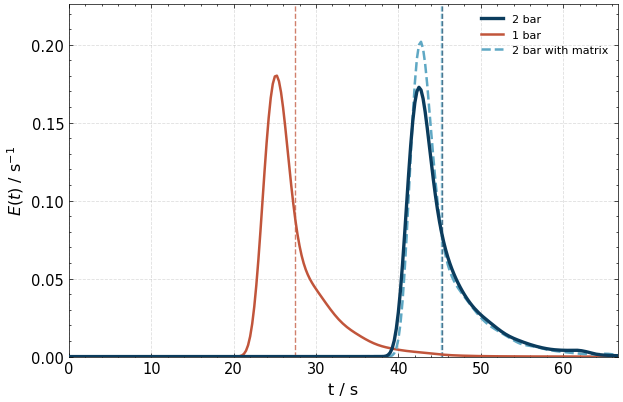

In [4]:
"""
===============================================================================
 Figure 1: overall residence time distribution  E1 (x) E2 (x) E3 (x) E4
===============================================================================

"""

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------- settings ------------------------------------
REFERENCE = '2 bar'      # gets the prominent line; must be a key of FILES

ALIGN = 'none'           # 'none' = absolute time | 'onset' | 't50' | 'tau'
ONSET_LEVEL = 0.01       # F(t) = 1 % counts as the start (used for the table)
T_MAX = None             # axis end in s; None = automatic
TAU_MARKER = True        # dashed vertical line at the mean residence time
SAVE_AS = None           # e.g. 'total_rtd.pdf' - use a vector format
# -----------------------------------------------------------------------------

# Reference: solid, dark, thick. Others: thinner, distinguishable in greyscale
# as well, because line style carries the distinction and not colour alone.
STYLE_REF = dict(color='#0B3C5D', linestyle='-', lw=2.4, zorder=3)
STYLE_OTHERS = [dict(color='#C1553B', linestyle='-', lw=1.8, zorder=2),
                dict(color='#5FA8C4', linestyle='--', lw=1.8, zorder=2),
                dict(color='#7A8B99', linestyle=':', lw=1.8, zorder=2)]


def load_total_rtd(path, onset_level=ONSET_LEVEL):
    """Chain E1..E4 into the overall RTD.

    Convolving the kernels first and only then applying a signal is equivalent
    by associativity, but numerically cleaner: only one boundary effect arises.

    The factor dt appears because np.convolve forms a sum while the convolution
    is an integral:  int f(t') g(t-t') dt'  ~  sum * dt.
    """
    ks = load_kernels(path)

    dts = [k['dt'] for k in ks]
    if not np.allclose(dts, dts[0], rtol=1e-9, atol=1e-12):
        raise ValueError(f'{path}: kernels have different dt: {dts}')
    dt = float(dts[0])

    E_tot = ks[0]['E']
    for k in ks[1:]:
        E_tot = np.convolve(E_tot, k['E']) * dt

    t_tot = np.arange(E_tot.size) * dt
    E_tot = E_tot / _trapz(E_tot, t_tot)

    F = np.concatenate(([0.0], np.cumsum(0.5 * (E_tot[1:] + E_tot[:-1]) * dt)))
    F = F / F[-1]

    tau, sigma = _moments(t_tot, E_tot)

    return {'t': t_tot, 'E': E_tot, 'F': F, 'dt': dt,
            'tau': tau, 'sigma': sigma,
            't50': float(np.interp(0.50, F, t_tot)),
            't10': float(np.interp(0.10, F, t_tot)),
            't90': float(np.interp(0.90, F, t_tot)),
            't_onset': float(np.interp(onset_level, F, t_tot)),
            'kernels': ks}


def shift_of(r, mode=ALIGN):
    """Time shift that puts the chosen reference point at t = 0."""
    return {'onset': r['t_onset'], 't50': r['t50'], 'tau': r['tau']}.get(mode, 0.0)


def style_for(name, index):
    if name == REFERENCE:
        return dict(STYLE_REF)
    others = [n for n in FILES if n != REFERENCE]
    return dict(STYLE_OTHERS[others.index(name) % len(STYLE_OTHERS)])


# ================================ computation ================================
res = {name: load_total_rtd(path) for name, path in FILES.items()}
runs = {name: r['kernels'] for name, r in res.items()}

if REFERENCE not in res:
    raise KeyError(f'REFERENCE = {REFERENCE!r} is not a key of FILES: {list(FILES)}')

label_x = {'onset': 'Time after onset / s',
           't50': 'Time relative to the median residence time / s',
           'tau': 'Time relative to the mean residence time / s',
           'none': 't / s'}[ALIGN]

print('=' * 100)
print(f'Overall RTD   E1 (x) E2 (x) E3 (x) E4        alignment: {ALIGN}')
print('=' * 100)
print(f'{"run":22s} {"tau / s":>9s} {"sigma / s":>10s} {"sigma^2 / s^2":>13s} '
      f'{"t50 / s":>9s} {"t10-90 / s":>11s} {"dead time":>10s} {"sigma/tau":>10s} {"shift":>9s}')
print('-' * 100)
for name, r in res.items():
    print(f'{name:22s} {r["tau"]:9.2f} {r["sigma"]:10.2f} {r["sigma"] ** 2:13.2f} '
          f'{r["t50"]:9.2f} {r["t90"] - r["t10"]:11.2f} {r["t_onset"]:10.2f} '
          f'{r["sigma"] / r["tau"]:10.4f} {-shift_of(r):8.2f}s')
print('-' * 100)
print('sigma/tau is the dimensionless spread: small means close to plug flow.')
print('It is independent of the dead time and therefore the fairest comparison')
print('between runs with different dead volume.')
print()

# --- the two independent checks for Section 4.2 ---
print_kernel_table(runs, KERNEL_NAME)
print_additivity_check(runs, res, KERNEL_NAME)

# --- differences against the reference, as numbers for the text ---
ref = res[REFERENCE]
print('=' * 100)
print(f'Differences against the reference case "{REFERENCE}"')
print('=' * 100)
print(f'{"run":22s} {"d tau / s":>10s} {"d sigma / s":>12s} {"d t50 / s":>10s} '
      f'{"d sigma / %":>12s}')
print('-' * 100)
for name, r in res.items():
    if name == REFERENCE:
        continue
    print(f'{name:22s} {r["tau"] - ref["tau"]:10.2f} {r["sigma"] - ref["sigma"]:12.2f} '
          f'{r["t50"] - ref["t50"]:10.2f} {(r["sigma"] / ref["sigma"] - 1) * 100:11.1f} %')
print()

# ================================== plot =====================================
fig, ax = plt.subplots(figsize=(6.4, 4.2))

for i, (name, r) in enumerate(res.items()):
    t = r['t'] - shift_of(r)
    st = style_for(name, i)
    ax.plot(t, r['E'],
            label=f'{name}',#  ($\\tau$ = {r["tau"]:.2f} s, $\\sigma$ = {r["sigma"]:.2f} s)',
                        **st)
    # mean residence time as a dashed vertical line, same colour as the curve,
    # consistent with the kernel figure
    if TAU_MARKER:
        ax.axvline(r['tau'] - shift_of(r), color=st['color'], linestyle='--',
                   lw=1.0, alpha=0.75, zorder=1)

ax.set_xlabel(label_x,
              fontsize=11.5)
ax.set_ylabel(r'$E(t)$ / s$^{-1}$', fontsize=11.5)
#ax.set_title('Density function of the overall RTD', fontsize=11)
ax.legend(fontsize=8, frameon=False)
ax.grid(alpha=0.25, lw=0.6)
ax.tick_params(labelsize=10.5)
ax.set_axisbelow(True)

# right: until every curve has reached F = 99.5 %
# left: only a small margin before the reference point, otherwise the axis
# reaches back to -tau and the interesting region is pushed to the right edge.
t_end = (max(np.interp(0.995, r['F'], r['t']) - shift_of(r) for r in res.values())
         if T_MAX is None else T_MAX)
t_raw = min((r['t'] - shift_of(r))[0] for r in res.values())
t_start = 0.0 if ALIGN == 'none' else max(t_raw, -0.08 * t_end)
ax.set_xlim(t_start, t_end * 1.03)
ax.set_ylim(0, max(float(np.max(r['E'])) for r in res.values()) * 1.12)

plt.tight_layout()
if SAVE_AS:
    plt.savefig(SAVE_AS, dpi=1000, bbox_inches='tight')
    print(f'saved: {SAVE_AS}')
plt.show()



Individual kernels: moments per stage   (sigma = standard deviation in s)
run                                  E1               E2               E3               E4
----------------------------------------------------------------------------------------------------
2 bar                     14.60 /  1.40    16.53 /  3.48    11.82 /  0.73     2.26 /  2.25      (tau / sigma in s)
1 bar                      7.94 /  1.69     6.75 /  2.71    10.44 /  1.28     2.24 /  2.19      (tau / sigma in s)
2 bar with matrix         16.64 /  1.60    13.29 /  3.28    12.93 /  0.43     2.25 /  2.15      (tau / sigma in s)
----------------------------------------------------------------------------------------------------

Spread across the runs, per stage   (max - min, relative to the mean)
stage                    tau spread   sigma spread   note
----------------------------------------------------------------------------------------------------
E1  inlet piping              66.6 %          18.9 %   
E2

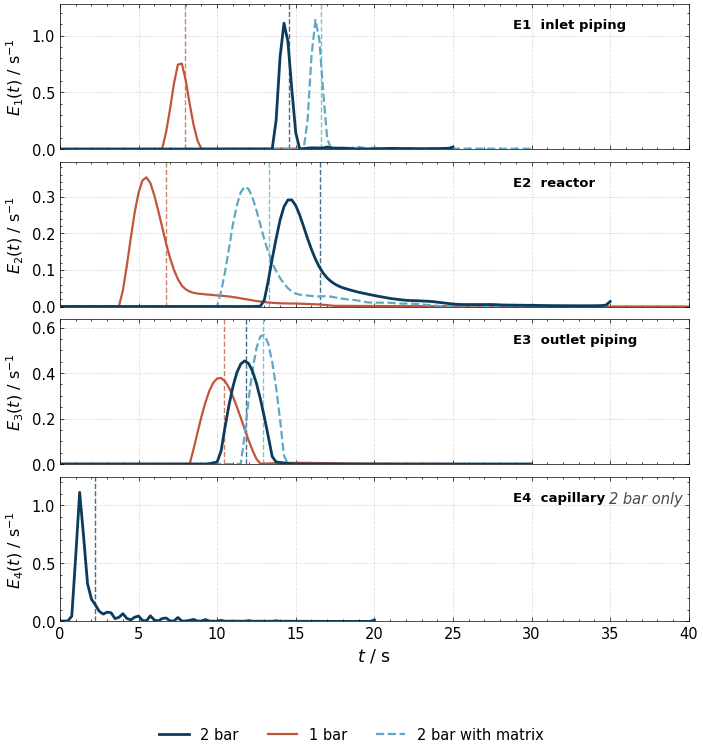

In [5]:
"""
===============================================================================
 Figure 2: individual kernels E1 to E4   -   layout following Stagge et al. 2026
===============================================================================

"""

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------- settings ------------------------------------
KERNEL_NAME = ['E1  inlet piping', 'E2  reactor',
               'E3  outlet piping', 'E4  capillary']

REFERENCE = '2 bar'        # prominent line, and the run shown for E4
SINGLE_LINE_STAGES = [3]   # stages drawn with the reference run only (E4)

T_MAX = None               # common x axis end in s; None = automatic
TAU_MARKER = True          # dashed vertical line at tau_i, as in Stagge Fig. 8
                           # (no numbers, just the marker - set False to drop it)
LEGEND_BELOW = True        # one shared legend under the panels instead of four
MARK_SINGLE_PANEL = True   # note in a single-line panel that only one run is shown
Y_HEADROOM = 1.12          # top margin per panel
ANNOTATE_E4_CAVEAT = True  # short note about E4' in the E4 panel
SAVE_AS = None             # e.g. 'kernels.pdf' - use a vector format
# -----------------------------------------------------------------------------

STYLE_REF = dict(color='#0B3C5D', linestyle='-', lw=2.0, zorder=3)
STYLE_OTHERS = [dict(color='#C1553B', linestyle='-', lw=1.6, zorder=2),
                dict(color='#5FA8C4', linestyle='--', lw=1.6, zorder=2),
                dict(color='#7A8B99', linestyle=':', lw=1.6, zorder=2)]


def style_for(name):
    if name == REFERENCE:
        return dict(STYLE_REF)
    others = [n for n in FILES if n != REFERENCE]
    return dict(STYLE_OTHERS[others.index(name) % len(STYLE_OTHERS)])


# ================================ computation ================================
runs = {name: load_kernels(path) for name, path in FILES.items()}
n_k = min(len(v) for v in runs.values())

if REFERENCE not in runs:
    raise KeyError(f'REFERENCE = {REFERENCE!r} is not a key of FILES: {list(FILES)}')

print('=' * 100)
print('Individual kernels: moments per stage   (sigma = standard deviation in s)')
print('=' * 100)
print(f'{"run":22s} ' + ' '.join(f'{KERNEL_NAME[i].split()[0]:>16s}' for i in range(n_k)))
print('-' * 100)
for name, ks in runs.items():
    cells = ' '.join(f'{k["tau"]:8.2f} /{k["sigma"]:6.2f}' for k in ks[:n_k])
    print(f'{name:22s} {cells}      (tau / sigma in s)')
print('-' * 100)
print()

# --- justification for drawing a single line: how well does the stage reproduce? ---
print('=' * 100)
print('Spread across the runs, per stage   (max - min, relative to the mean)')
print('=' * 100)
print(f'{"stage":22s} {"tau spread":>12s} {"sigma spread":>14s}   note')
print('-' * 100)
for i in range(n_k):
    taus = [ks[i]['tau'] for ks in runs.values()]
    sigs = [ks[i]['sigma'] for ks in runs.values()]
    d_tau = (max(taus) - min(taus)) / np.mean(taus) * 100
    d_sig = (max(sigs) - min(sigs)) / np.mean(sigs) * 100
    note = 'single line in the figure' if i in SINGLE_LINE_STAGES else ''
    print(f'{KERNEL_NAME[i]:22s} {d_tau:11.1f} % {d_sig:13.1f} %   {note}')
print('-' * 100)
print('Quote the E4 numbers in the caption: they justify showing one line instead')
print('of three, and they are an internal consistency check - the capillary sees')
print('atmospheric pressure and the same MS draw in every run, so it must reproduce.')
print()

# --- stage-wise comparison against the reference ---
ref_ks = runs[REFERENCE]
print('=' * 100)
print(f'Stage-wise change of the dispersion against "{REFERENCE}"')
print('=' * 100)
print(f'{"run":22s} ' + ' '.join(f'{KERNEL_NAME[i].split()[0]:>14s}' for i in range(n_k)))
print('-' * 100)
for name, ks in runs.items():
    if name == REFERENCE:
        continue
    cells = ' '.join(f'{(ks[i]["sigma"] / ref_ks[i]["sigma"] - 1) * 100:12.1f} %'
                     for i in range(n_k))
    print(f'{name:22s} {cells}')
print('-' * 100)
print('The back-pressure regulator sits inside E3 and the matrix is fed at the')
print('reactor outlet, so a pressure or matrix effect is expected there first')
print('(Stagge et al. 2026, Section 4.3).')
print()

# ================================== plot =====================================
# Stacked panels on one shared, absolute time axis - Stagge et al. 2026, Fig. 8.
fig, axes = plt.subplots(n_k, 1, figsize=(7.2, 1.85 * n_k), sharex=True)
axes = np.atleast_1d(axes)

t_end = (max(k['t'][-1] for ks in runs.values() for k in ks[:n_k])
         if T_MAX is None else T_MAX)

for i in range(n_k):
    ax = axes[i]
    single = i in SINGLE_LINE_STAGES
    shown = {REFERENCE: runs[REFERENCE]} if single else runs

    y_max = 0.0
    for name, ks in shown.items():
        k = ks[i]
        st = style_for(name)
        # Labels carry the run name only. tau and sigma belong in the table,
        # not in the figure - repeating them here would duplicate the numbers
        # that the printout above already produces for the text.
        ax.plot(k['t'], k['E'], label=name, **st)
        y_max = max(y_max, float(np.max(k['E'])))

        # tau as a dashed vertical line, same colour as the curve
        if TAU_MARKER:
            ax.axvline(k['tau'], color=st['color'], linestyle='--',
                       lw=1.0, alpha=0.75, zorder=1)

    ax.set_ylabel(rf'$E_{i + 1}(t)$ / s$^{{-1}}$', fontsize=11.5)
    ax.set_ylim(0, y_max * Y_HEADROOM)
    ax.set_xlim(0, t_end)
    ax.grid(alpha=0.25, lw=0.6)
    ax.tick_params(labelsize=10.5)
    ax.set_axisbelow(True)

    # compartment name inside the panel, so the stack stays compact
    ax.text(0.72, 0.90, KERNEL_NAME[i], transform=ax.transAxes,
            ha='left', va='top', fontsize=9.5, fontweight='bold')
    if not LEGEND_BELOW:
        ax.legend(fontsize=10.5, frameon=False, loc='upper right')

    # A panel that shows only the reference run must say so, otherwise the
    # shared legend implies three curves where only one is drawn.
    if single and MARK_SINGLE_PANEL:
        ax.text(0.99, 0.90, f'{REFERENCE} only', transform=ax.transAxes,
                ha='right', va='top', fontsize=10.5, color='#4A4A4A',
                style='italic')





axes[-1].set_xlabel('$t$ / s', fontsize=12.5)

fig.align_ylabels(axes)
plt.tight_layout(h_pad=0.4)

# One legend for the whole figure. Handles are taken from a panel that shows
# every run, so a single-line panel does not truncate the legend.
if LEGEND_BELOW:
    src = next((ax for i, ax in enumerate(axes) if i not in SINGLE_LINE_STAGES), axes[0])
    handles, labels = src.get_legend_handles_labels()
    fig.legend(handles, labels, loc='center', frameon=False,
               ncol=min(len(labels), 4), fontsize=10.5,
               bbox_to_anchor=(0.5, -0.005))
    fig.subplots_adjust(bottom=0.10 + 0.012 * n_k)
if SAVE_AS:
    plt.savefig(SAVE_AS, dpi=1000, bbox_inches='tight')
    print(f'saved: {SAVE_AS}')
plt.show()


In [6]:
"""
===============================================================================
 PERIOD-TO-PERIOD SCATTER  -  uncertainty of t50 and t10-90
===============================================================================

WHY THIS IS NEEDED
------------------
Every characteristic time in the report is quoted to 0.01 s. Without a scatter
there is no way to say whether a difference of 0.06 s between two conditions
is real. This cell supplies that number.

WHERE IT COMES FROM
-------------------
The training files store the INDIVIDUAL step responses under 'x_out <config>',
not only their average. Each row is one half period, already referred to the
switching event. Applying the same t50 and t10-90 evaluation to every row and
taking the standard deviation over the rows gives the scatter directly.

Reported is the scatter of the INDIVIDUAL cycles, not of their mean. The mean
of n cycles scatters by a factor sqrt(n) less, so using it would overstate the
resolution. For the question "is this difference real", the individual-cycle
scatter is the conservative and correct choice.

Rows alternate between the tracer and a second component that barely steps;
the latter is rejected by its small amplitude. With n = 5 per flank the
standard deviation itself carries about 35 % relative uncertainty, which is
enough for a resolution limit but not for a precise error bar. Say so in the
report.
===============================================================================
"""
import numpy as np

CONFIG_KEYS = ['cap', 'inlet', 'outlet', 'total']
CONFIG_LABEL = {'cap': 'A  capillary', 'inlet': 'B  inlet piping',
                'outlet': 'C  reactor outlet', 'total': 'D  total system'}

# Configurations entering the resolution limit quoted in the report.
# A is excluded: its data were replaced for the identification (Section 3.1).
LIMIT_CONFIGS = ['inlet', 'outlet', 'total']

AMPLITUDE_FRACTION = 0.5   # rows below this share of the largest span are rejected
BASE_POINTS = 6            # points averaged for the baseline
PLATEAU_POINTS = 40        # points averaged for the plateau


def _cross(t, y, level, rising):
    """First crossing of `level`, linearly interpolated between two samples."""
    hit = np.flatnonzero(y >= level) if rising else np.flatnonzero(y <= level)
    if hit.size == 0:
        return np.nan
    i = int(hit[0])
    if i == 0:
        return float(t[0])
    y0, y1 = float(y[i - 1]), float(y[i])
    if y1 == y0:
        return float(t[i])
    return float(t[i - 1] + (level - y0) * (t[i] - t[i - 1]) / (y1 - y0))


def _single_flank(t, y, rising):
    """t50 and width of one individual step response, normalised to 0..1."""
    if rising:
        base = float(np.mean(y[:BASE_POINTS]))
        top = float(np.mean(y[-PLATEAU_POINTS:]))
    else:
        base = float(np.mean(y[-PLATEAU_POINTS:]))
        top = float(np.mean(y[:BASE_POINTS]))
    if abs(top - base) < 1e-12:
        return np.nan, np.nan
    F = (y - base) / (top - base)
    t50 = _cross(t, F, 0.5, rising)
    if rising:
        width = _cross(t, F, 0.9, True) - _cross(t, F, 0.1, True)
    else:
        width = _cross(t, F, 0.1, False) - _cross(t, F, 0.9, False)
    return t50, width


def period_scatter(path, label='', verbose=True):
    """Scatter of t50 and width over the individual cycles, per configuration."""
    d = np.load(path, allow_pickle=True)
    d = d.item() if isinstance(d, np.ndarray) and d.ndim == 0 else d

    rows = []
    for cfg in CONFIG_KEYS:
        kt, kx = f't_out {cfg}', f'x_out {cfg}'
        if kt not in d or kx not in d:
            continue
        t = np.asarray(d[kt], float)
        x = np.asarray(d[kx], float)
        x = x[:, 0, :] if x.ndim == 3 else x

        span = x.max(1) - x.min(1)
        amp = x[:, -1] - x[:, 0]
        tracer = span > AMPLITUDE_FRACTION * span.max()   # reject the flat component

        for flank, sel in (('rise', tracer & (amp > 0)),
                           ('fall', tracer & (amp < 0))):
            idx = np.flatnonzero(sel)
            if idx.size < 2:
                continue
            vals = [_single_flank(t[i], x[i], flank == 'rise') for i in idx]
            t50 = np.array([v[0] for v in vals], float)
            w = np.array([v[1] for v in vals], float)
            ok = np.isfinite(t50) & np.isfinite(w)
            rows.append({'run': label, 'config': cfg, 'flank': flank,
                         'n': int(ok.sum()),
                         't50_mean': float(t50[ok].mean()),
                         't50_sd': float(t50[ok].std(ddof=1)),
                         'w_mean': float(w[ok].mean()),
                         'w_sd': float(w[ok].std(ddof=1))})

    if verbose:
        print('-' * 92)
        print(f'{label}')
        print('-' * 92)
        print(f'{"configuration":20s} {"flank":6s} {"n":>3s} {"t50":>8s} {"sd(t50)":>9s} '
              f'{"width":>8s} {"sd(width)":>10s}')
        for r in rows:
            print(f'{CONFIG_LABEL.get(r["config"], r["config"]):20s} {r["flank"]:6s} '
                  f'{r["n"]:3d} {r["t50_mean"]:8.2f} {r["t50_sd"]:9.3f} '
                  f'{r["w_mean"]:8.2f} {r["w_sd"]:10.3f}')
    return rows


def resolution_limit(all_rows, configs=LIMIT_CONFIGS):
    """The two numbers quoted in the report: the worst case over all runs.

    Configuration A is excluded by default. Its data were replaced for the
    identification, and its scatter is three times larger than that of the
    other configurations, so including it would overstate the limit for
    statements that concern B, C and D.
    """
    sel = [r for r in all_rows if r['config'] in configs]
    if not sel:
        print('no rows selected')
        return None, None

    t50_max = max(r['t50_sd'] for r in sel)
    w_max = max(r['w_sd'] for r in sel)
    t50_arg = max(sel, key=lambda r: r['t50_sd'])
    w_arg = max(sel, key=lambda r: r['w_sd'])

    print()
    print('=' * 92)
    print('RESOLUTION LIMIT over ' + ', '.join(CONFIG_LABEL[c] for c in configs))
    print('=' * 92)
    print(f'  median   max sd = {t50_max:.3f} s   '
          f'({t50_arg["run"]}, {CONFIG_LABEL[t50_arg["config"]]}, {t50_arg["flank"]})')
    print(f'  width    max sd = {w_max:.3f} s   '
          f'({w_arg["run"]}, {CONFIG_LABEL[w_arg["config"]]}, {w_arg["flank"]})')
    print()
    print(f'  -> for the report: at most {np.ceil(t50_max * 100) / 100:.2f} s for the '
          f'median and {np.ceil(w_max * 100) / 100:.2f} s for the width.')

    excluded = sorted({r['config'] for r in all_rows} - set(configs))
    if excluded:
        print(f'  excluded: {", ".join(CONFIG_LABEL.get(c, c) for c in excluded)}')
        for c in excluded:
            sub = [r for r in all_rows if r['config'] == c]
            if sub:
                print(f'     {CONFIG_LABEL.get(c, c)}: max sd(t50) = '
                      f'{max(r["t50_sd"] for r in sub):.3f} s, '
                      f'max sd(width) = {max(r["w_sd"] for r in sub):.3f} s')
    print()
    print('n = 5 per flank, so the standard deviation itself carries roughly 35 %')
    print('relative uncertainty. These values are the scatter of the individual')
    print('cycles, not of their mean.')
    return t50_max, w_max


def scatter_table_for_si(all_rows, path=None):
    """Full table for the supporting information."""
    lines = ['run\tconfiguration\tflank\tn\tt50 / s\tsd(t50) / s\twidth / s\tsd(width) / s']
    for r in all_rows:
        lines.append(f'{r["run"]}\t{CONFIG_LABEL.get(r["config"], r["config"])}\t'
                     f'{r["flank"]}\t{r["n"]}\t{r["t50_mean"]:.2f}\t{r["t50_sd"]:.3f}\t'
                     f'{r["w_mean"]:.2f}\t{r["w_sd"]:.3f}')
    text = '\n'.join(lines)
    if path:
        open(path, 'w', encoding='utf-8').write(text)
        print(f'written: {path}')
    else:
        print()
        print(text)
    return text


# =============================================================================
#  EVALUATION  -  all three runs
# =============================================================================
all_rows = []
for name, path in FILES.items():
    all_rows += period_scatter(path, label=name)

resolution_limit(all_rows)

# Table for the supporting information; pass a file name to write it out.
scatter_table_for_si(all_rows)

--------------------------------------------------------------------------------------------
2 bar
--------------------------------------------------------------------------------------------
configuration        flank    n      t50   sd(t50)    width  sd(width)
A  capillary         rise    10     2.31     0.112     3.15      0.207
A  capillary         fall    10     2.33     0.123     3.33      0.399
B  inlet piping      rise     5    16.77     0.019     4.96      0.259
B  inlet piping      fall     5    16.75     0.026     4.27      0.060
C  reactor outlet    rise     5    32.83     0.018    10.41      0.144
C  reactor outlet    fall     5    32.71     0.018     9.11      0.030
D  total system      rise     5    44.57     0.020    10.31      0.241
D  total system      fall     5    44.75     0.020     9.35      0.038
--------------------------------------------------------------------------------------------
1 bar
----------------------------------------------------------------------

'run\tconfiguration\tflank\tn\tt50 / s\tsd(t50) / s\twidth / s\tsd(width) / s\n2 bar\tA  capillary\trise\t10\t2.31\t0.112\t3.15\t0.207\n2 bar\tA  capillary\tfall\t10\t2.33\t0.123\t3.33\t0.399\n2 bar\tB  inlet piping\trise\t5\t16.77\t0.019\t4.96\t0.259\n2 bar\tB  inlet piping\tfall\t5\t16.75\t0.026\t4.27\t0.060\n2 bar\tC  reactor outlet\trise\t5\t32.83\t0.018\t10.41\t0.144\n2 bar\tC  reactor outlet\tfall\t5\t32.71\t0.018\t9.11\t0.030\n2 bar\tD  total system\trise\t5\t44.57\t0.020\t10.31\t0.241\n2 bar\tD  total system\tfall\t5\t44.75\t0.020\t9.35\t0.038\n1 bar\tA  capillary\trise\t10\t2.31\t0.112\t3.15\t0.207\n1 bar\tA  capillary\tfall\t10\t2.33\t0.123\t3.33\t0.399\n1 bar\tB  inlet piping\trise\t5\t10.03\t0.018\t4.80\t0.036\n1 bar\tB  inlet piping\tfall\t5\t10.03\t0.039\t4.03\t0.056\n1 bar\tC  reactor outlet\trise\t5\t16.54\t0.030\t8.76\t0.196\n1 bar\tC  reactor outlet\tfall\t5\t16.50\t0.010\t7.81\t0.029\n1 bar\tD  total system\trise\t5\t26.97\t0.015\t9.25\t0.066\n1 bar\tD  total system\

In [7]:
def diagnose_scatter(path, label='', cfg=None):
    """Three checks on where a large scatter comes from.

    1  individual cycles instead of the standard deviation alone
       A single outlier among five values inflates the standard deviation by
       roughly a factor of two. The median absolute deviation does not react
       to it, so a large ratio of the two identifies that case.

    2  placement of the baseline and plateau windows
       The windows are taken as a fixed number of points at the start and end
       of each row. If a signal is shifted within its array, those points may
       no longer lie on the plateau. Reported is where the windows actually
       fall relative to the flank.

    3  whether two runs share the same raw data
       Two runs can contain the same measurement on a shifted time axis. The
       widths then agree while the medians differ by the shift.
    """
    d = np.load(path, allow_pickle=True)
    d = d.item() if isinstance(d, np.ndarray) and d.ndim == 0 else d

    for c in ([cfg] if cfg else CONFIG_KEYS):
        if f'x_out {c}' not in d:
            continue
        t = np.asarray(d[f't_out {c}'], float)
        x = np.asarray(d[f'x_out {c}'], float)
        x = x[:, 0, :] if x.ndim == 3 else x
        span = x.max(1) - x.min(1)
        amp = x[:, -1] - x[:, 0]
        tracer = span > AMPLITUDE_FRACTION * span.max()

        for flank, sel in (('rise', tracer & (amp > 0)),
                           ('fall', tracer & (amp < 0))):
            idx = np.flatnonzero(sel)
            if idx.size < 2:
                continue
            vals = [_single_flank(t[i], x[i], flank == 'rise') for i in idx]
            t50 = np.array([v[0] for v in vals])
            w = np.array([v[1] for v in vals])

            # 1 individual values and a robust spread
            mad_w = 1.4826 * np.median(np.abs(w - np.median(w)))
            mad_t = 1.4826 * np.median(np.abs(t50 - np.median(t50)))
            print(f'{label} {CONFIG_LABEL[c]} {flank}')
            print('   t50   ' + '  '.join(f'{v:7.3f}' for v in t50) +
                  f'   sd {t50.std(ddof=1):.3f}  mad {mad_t:.3f}')
            print('   width ' + '  '.join(f'{v:7.3f}' for v in w) +
                  f'   sd {w.std(ddof=1):.3f}  mad {mad_w:.3f}')
            if w.std(ddof=1) > 2 * max(mad_w, 1e-6):
                print('   -> scatter dominated by a single cycle, not by noise')

            # 2 where the windows fall
            row = x[idx[0]]
            base = row[:BASE_POINTS].mean() if flank == 'rise' else row[-PLATEAU_POINTS:].mean()
            top = row[-PLATEAU_POINTS:].mean() if flank == 'rise' else row[:BASE_POINTS].mean()
            F = (row - base) / (top - base)
            print(f'   F at end of base window  {F[BASE_POINTS - 1]:+.4f}   '
                  f'F at start of plateau window {F[-PLATEAU_POINTS]:+.4f}')
            print('   (should be close to 0 and 1; otherwise the windows sit on the flank)')


def same_measurement(path_a, path_b, cfg, label_a='', label_b=''):
    """Do two runs contain the same raw data, up to a shift of the time axis?"""
    out = []
    for p in (path_a, path_b):
        d = np.load(p, allow_pickle=True)
        d = d.item() if isinstance(d, np.ndarray) and d.ndim == 0 else d
        x = np.asarray(d[f'x_out {cfg}'], float)
        out.append(x[:, 0, :] if x.ndim == 3 else x)
    a, b = out
    if a.shape != b.shape:
        print(f'{cfg}: different shapes {a.shape} vs {b.shape}')
        return
    print(f'{cfg}: max |a - b| = {np.max(np.abs(a - b)):.3e}   '
          f'identical: {np.allclose(a, b)}')
    # same data on a shifted axis shows up as a best lag other than zero
    s = a[0] - a[0].mean()
    r = b[0] - b[0].mean()
    lag = int(np.argmax(np.correlate(s, r, 'full')) - (s.size - 1))
    print(f'   best lag of the first row: {lag} samples')

In [8]:
diagnose_scatter(FILES['2 bar with matrix'], '2 bar matrix', cfg='outlet')
diagnose_scatter(FILES['2 bar'], '2 bar', cfg='outlet')
same_measurement(FILES['2 bar'], FILES['2 bar with matrix'], 'inlet')

2 bar matrix C  reactor outlet rise
   t50    31.724   31.749   31.801   31.664   31.673   sd 0.056  mad 0.076
   width   9.445    9.520    9.400    9.158    8.844   sd 0.276  mad 0.178
   F at end of base window  -0.0000   F at start of plateau window +0.9974
   (should be close to 0 and 1; otherwise the windows sit on the flank)
2 bar matrix C  reactor outlet fall
   t50    31.684   31.702   31.684   31.692   31.725   sd 0.017  mad 0.011
   width   8.224    8.260    8.265    8.261    8.222   sd 0.022  mad 0.008
   -> scatter dominated by a single cycle, not by noise
   F at end of base window  +0.9992   F at start of plateau window +0.0001
   (should be close to 0 and 1; otherwise the windows sit on the flank)
2 bar C  reactor outlet rise
   t50    32.843   32.848   32.840   32.806   32.818   sd 0.018  mad 0.012
   width  10.166   10.470   10.423   10.479   10.533   sd 0.144  mad 0.069
   -> scatter dominated by a single cycle, not by noise
   F at end of base window  -0.0000   F at 

In [9]:
"""
===============================================================================
 TWO CHECKS
===============================================================================

 1  cycle_trend()     Is the scatter between cycles random, or a drift?
 2  compare_runs()    Why do two runs disagree for the same configuration?

CHECK 1
-------
A standard deviation treats five values as five independent draws. If they
instead run monotonically from the first cycle to the last, the setup has not
stabilised and the number is a drift, not noise. The two cases call for
different statements in the report, so they have to be told apart.

Three indicators are reported per flank:
  trend     slope of a straight line through the values over the cycle index,
            and the fraction of the variance it explains. A high fraction
            means a drift.
  spearman  rank correlation with the cycle index. +1 or -1 means strictly
            monotonic. Robust against a single outlier.
  residual  scatter remaining after the trend is removed. This is the part
            that is genuinely random and the better basis for a resolution
            limit if a drift is present.

CHECK 2
-------
Two runs can disagree for the same configuration for three reasons, and they
are distinguishable: the same data on a shifted time axis (widths agree,
medians differ by the shift, and the signals match after shifting), different
operating conditions (widths differ as well), or different normalisation of
the same signal (shapes match after rescaling). The function reports the
evidence for each rather than deciding.
===============================================================================
"""
import numpy as np

try:
    from scipy.stats import spearmanr
except ImportError:
    spearmanr = None


def _flank_rows(d, cfg):
    """Individual step responses of one configuration, split by flank."""
    t = np.asarray(d[f't_out {cfg}'], float)
    x = np.asarray(d[f'x_out {cfg}'], float)
    x = x[:, 0, :] if x.ndim == 3 else x
    span = x.max(1) - x.min(1)
    amp = x[:, -1] - x[:, 0]
    tracer = span > AMPLITUDE_FRACTION * span.max()
    return t, x, {'rise': np.flatnonzero(tracer & (amp > 0)),
                  'fall': np.flatnonzero(tracer & (amp < 0))}


def _load(path):
    d = np.load(path, allow_pickle=True)
    return d.item() if isinstance(d, np.ndarray) and d.ndim == 0 else d


def cycle_trend(path, label='', configs=None, trend_fraction=0.6, rho_limit=0.9):
    """Separate drift from random scatter, per configuration and flank."""
    d = _load(path)
    configs = configs or CONFIG_KEYS
    print('=' * 96)
    print(f'{label}   drift check')
    print('=' * 96)
    print(f'{"configuration":20s} {"flank":5s} {"quantity":7s} {"sd":>7s} '
          f'{"slope/cyc":>10s} {"R2_trend":>9s} {"spearman":>9s} {"sd_resid":>9s}')
    print('-' * 96)

    flagged = []
    for cfg in configs:
        if f'x_out {cfg}' not in d:
            continue
        t, x, sel = _flank_rows(d, cfg)
        for flank, idx in sel.items():
            if idx.size < 4:
                continue
            vals = [_single_flank(t[i], x[i], flank == 'rise') for i in idx]
            series = {'t50': np.array([v[0] for v in vals], float),
                      'width': np.array([v[1] for v in vals], float)}
            k = np.arange(idx.size, dtype=float)      # cycle index, in order

            for name, y in series.items():
                ok = np.isfinite(y)
                if ok.sum() < 4:
                    continue
                yy, kk = y[ok], k[ok]
                slope, icpt = np.polyfit(kk, yy, 1)
                pred = slope * kk + icpt
                ss_tot = float(np.sum((yy - yy.mean()) ** 2))
                r2 = 1 - float(np.sum((yy - pred) ** 2)) / ss_tot if ss_tot > 0 else np.nan
                resid = float(np.std(yy - pred, ddof=1)) if yy.size > 2 else np.nan
                rho = (float(spearmanr(kk, yy).statistic) if spearmanr is not None
                       else np.nan)

                drift = (r2 >= trend_fraction) and (abs(rho) >= rho_limit if
                                                    np.isfinite(rho) else True)
                mark = '  <- drift' if drift else ''
                if drift:
                    flagged.append((cfg, flank, name, yy.std(ddof=1), resid))
                print(f'{CONFIG_LABEL.get(cfg, cfg):20s} {flank:5s} {name:7s} '
                      f'{yy.std(ddof=1):7.3f} {slope:10.3f} {r2:9.3f} {rho:9.2f} '
                      f'{resid:9.3f}{mark}')
            print('   values ' + ' '.join(f'{v:7.3f}' for v in series['width']))
    print('-' * 96)

    if flagged:
        print('A monotonic trend over consecutive cycles is not random scatter.')
        print('For those entries the standard deviation overstates the noise;')
        print('sd_resid is the random part that remains after removing the trend:')
        for cfg, flank, name, sd, resid in flagged:
            print(f'   {CONFIG_LABEL.get(cfg, cfg):20s} {flank:5s} {name:7s} '
                  f'sd {sd:.3f} -> {resid:.3f} s')
        print('Decide whether to quote the standard deviation as an upper bound')
        print('or the residual scatter as the resolution, and say which in the text.')
    else:
        print('No drift found: the standard deviations describe random scatter.')
    print()
    return flagged


def compare_runs(path_a, path_b, cfg, label_a='A', label_b='B', max_lag=200):
    """Why do two runs disagree for the same configuration?"""
    da, db = _load(path_a), _load(path_b)
    ta, xa, sa = _flank_rows(da, cfg)
    tb, xb, sb = _flank_rows(db, cfg)

    print('=' * 96)
    print(f'{CONFIG_LABEL.get(cfg, cfg)}:  {label_a}  vs  {label_b}')
    print('=' * 96)

    if xa.shape != xb.shape:
        print(f'different array shapes: {xa.shape} vs {xb.shape}')
        return

    ra, rb = xa[sa['rise'][0]], xb[sb['rise'][0]]
    dt = float(ta[sa['rise'][0]][1] - ta[sa['rise'][0]][0])

    print(f'raw difference      max |a - b| = {np.max(np.abs(ra - rb)):.4e}')
    print(f'plateau levels      a: {ra[-PLATEAU_POINTS:].mean():.5f}   '
          f'b: {rb[-PLATEAU_POINTS:].mean():.5f}   '
          f'ratio {rb[-PLATEAU_POINTS:].mean() / ra[-PLATEAU_POINTS:].mean():.4f}')
    print(f'baselines           a: {ra[:BASE_POINTS].mean():.5f}   '
          f'b: {rb[:BASE_POINTS].mean():.5f}')

    # characteristic times
    for lab, (tt, xx, ss) in ((label_a, (ta, xa, sa)), (label_b, (tb, xb, sb))):
        v = [_single_flank(tt[i], xx[i], True) for i in ss['rise']]
        t50 = np.mean([u[0] for u in v])
        w = np.mean([u[1] for u in v])
        print(f'{lab:12s} rise  t50 {t50:8.3f} s   width {w:7.3f} s')

    # best lag after normalising both to 0..1, so a level difference cannot
    # masquerade as a shift
    def norm(y):
        b = y[:BASE_POINTS].mean()
        p = y[-PLATEAU_POINTS:].mean()
        return (y - b) / (p - b)

    na, nb = norm(ra) - 0.5, norm(rb) - 0.5
    corr = np.correlate(na, nb, 'full')
    lag = int(np.argmax(corr) - (na.size - 1))
    lag = int(np.clip(lag, -max_lag, max_lag))
    print(f'best lag (normalised) {lag:+d} samples = {lag * dt:+.2f} s')

    if lag != 0:
        shifted = np.roll(nb, lag)
        inner = slice(abs(lag) + BASE_POINTS, -abs(lag) - PLATEAU_POINTS or None)
        print(f'after shifting        max |a - b| = '
              f'{np.max(np.abs(na[inner] - shifted[inner])):.4e}')
        print('   small  -> same measurement on a shifted time axis')
        print('   large  -> genuinely different measurements')
    else:
        print('no shift found, so the difference is not a time offset')
    print()


# =============================================================================
#  EVALUATION
# =============================================================================
for name, path in FILES.items():
    cycle_trend(path, label=name)

compare_runs(FILES['2 bar'], FILES['2 bar with matrix'], 'inlet',
             label_a='2 bar', label_b='2 bar with matrix')

2 bar   drift check
configuration        flank quantity      sd  slope/cyc  R2_trend  spearman  sd_resid
------------------------------------------------------------------------------------------------
A  capillary         rise  t50       0.112      0.000     0.000      0.01     0.112
A  capillary         rise  width     0.207     -0.005     0.004      0.02     0.207
   values   3.236   2.952   3.397   2.890   3.356   2.975   3.462   3.067   3.221   2.980
A  capillary         fall  t50       0.123      0.002     0.001      0.01     0.123
A  capillary         fall  width     0.399      0.005     0.001      0.18     0.399
   values   3.058   3.614   3.431   3.665   2.706   3.693   2.849   3.690   2.945   3.684
B  inlet piping      rise  t50       0.019     -0.005     0.191     -0.50     0.017
B  inlet piping      rise  width     0.259     -0.102     0.391     -0.90     0.202
   values   5.163   5.120   5.034   4.518   4.952
B  inlet piping      fall  t50       0.026     -0.007     0.167 